# Figure S3c–d — Runtime comparisons and scaling

Sources: `time_batch/new_pipeline_NKT_time.ipynb`, `time_batch/draw_time_350k.ipynb` and
`time_batch/draw_precomputed_pca_no_harmony_scaling.py`. Only bundled timing tables are read; training is not run.

S3c: colored intervals show mean +/- SD; black segments show saved 95% CIs; points are individual measured runs.
The caption says "boxes indicate 95% CI", which reverses the source-code convention. Preserve the code and clarify the legend.
S3d: the 23,666- and 352,496-cell datasets have repeated runs. The 2,122,065-cell dataset has n=1 and no CI is drawn.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [1]:
FIGURE = 'figS3'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
H5AD inputs: none (bundled result tables only)
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS3


In [2]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
TIMING_DIR = INPUT_DIR / 'figS3'
DATASETS = [(23666, 'time_results'), (352496, 'time_results_350k'), (2122065, 'time_results_2M')]
palette = ['#3B82F6', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6']
labels = ['Raw', 'PCA\nNo Harmony', 'PCA\nHarmony', 'Existing PCA\nNo Harmony', 'Existing PCA\nHarmony']

def timing_tables(directory):
    runs = pd.read_csv(require_file(TIMING_DIR / directory / 'NKT_recluster_timing_each_run.csv'))
    summary = pd.read_csv(require_file(TIMING_DIR / directory / 'NKT_recluster_timing_summary.csv'))
    for _, row in summary.iterrows():
        values = runs.loc[runs['config_id'] == row['config_id'], 'elapsed_seconds']
        if len(values) != int(row['n']) or not np.isclose(values.mean(), row['mean_seconds']):
            raise ValueError(f'{directory}: run-level values disagree with saved summary')
    return runs, summary.sort_values('config_id')

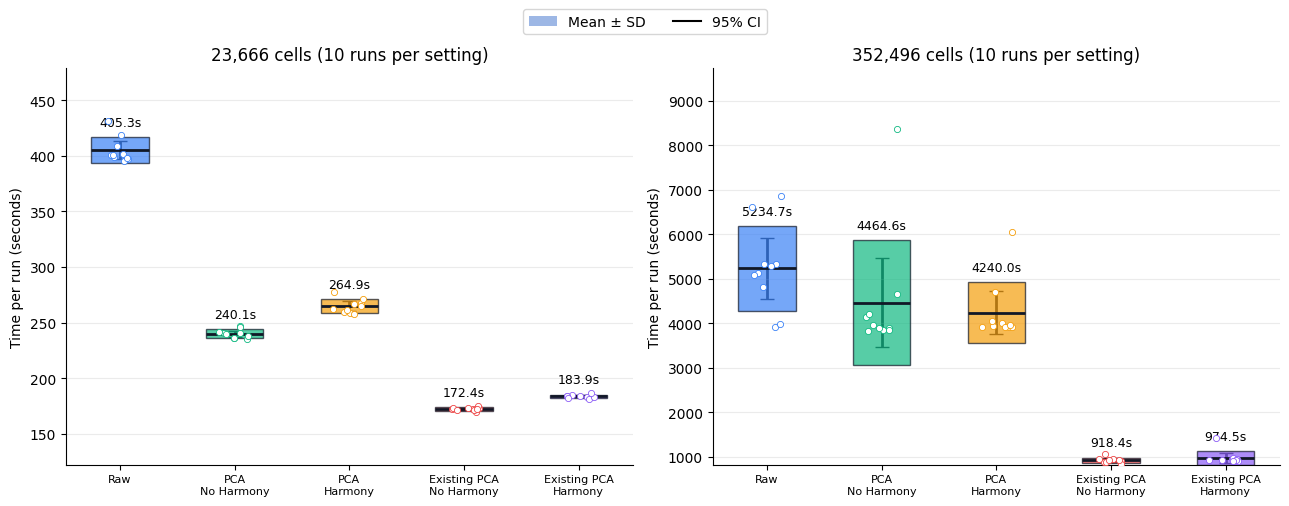

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
rng = np.random.default_rng(20240507)
for ax, (n_cells, directory) in zip(axes, DATASETS[:2]):
    runs, summary = timing_tables(directory)
    for x, (_, row) in enumerate(summary.iterrows()):
        mean, sd, ci = row['mean_seconds'], row['std_seconds'], row['ci95_seconds']
        ax.errorbar(x, mean, yerr=ci, color='#111827', capsize=5, linewidth=2, zorder=1)
        ax.bar(x, 2 * sd, bottom=mean - sd, width=0.5, color=palette[x],
               edgecolor='#111827', alpha=0.7, zorder=2)
        ax.hlines(mean, x-0.25, x+0.25, color='#111827', linewidth=2, zorder=3)
        values = runs.loc[runs['config_id'] == row['config_id'], 'elapsed_seconds'].to_numpy()
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(values)), values,
                   color='white', edgecolor=palette[x], s=20, linewidth=0.6, zorder=4)
        ax.annotate(f'{mean:.1f}s', (x, mean + max(sd, ci)), xytext=(0, 8),
                    textcoords='offset points', ha='center', fontsize=9)
    ax.set_xticks(range(len(summary)), labels, fontsize=8)
    ax.set_ylabel('Time per run (seconds)')
    ax.set_title(f'{n_cells:,} cells (10 runs per setting)')
    ax.grid(axis='y', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
    ax.margins(y=0.18)
fig.legend(handles=[Patch(facecolor='#9DB7E5', label='Mean ± SD'),
    Line2D([0], [0], color='black', label='95% CI')], loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
save_figure(fig, OUTPUT_DIR, 'figS3c_runtime_comparison')

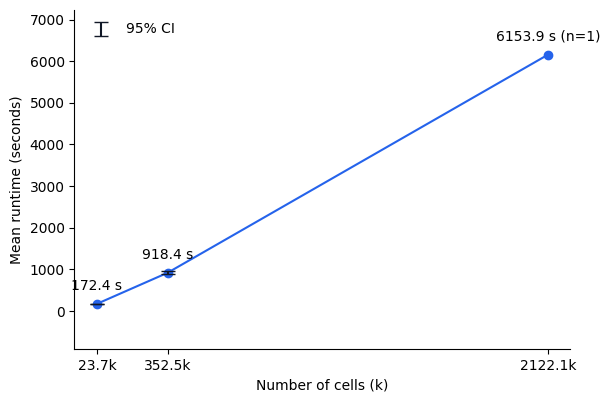

 cell_count  mean_seconds  n  ci95_seconds
      23666    172.430145 10      1.104200
     352496    918.449614 10     40.431315
    2122065   6153.948169  1           NaN


In [4]:
rows = []
for n_cells, directory in DATASETS:
    _, summary = timing_tables(directory)
    # Validate the requested configuration even when a CSV contains one row.
    matches = summary[summary['config'].str.contains('Existing PCA', na=False)
                      & summary['config'].str.contains('No Harmony', na=False)]
    if len(matches) != 1:
        raise ValueError(f'{directory}: expected one existing-PCA/no-Harmony row')
    row = matches.iloc[0]
    rows.append({'cell_count': n_cells, 'mean_seconds': row['mean_seconds'], 'n': int(row['n']),
                 'ci95_seconds': row['ci95_seconds'] if row['n'] > 1 else np.nan})
scaling = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
x = scaling['cell_count'].to_numpy() / 1000
y = scaling['mean_seconds'].to_numpy()
has_ci = scaling['n'].to_numpy() > 1
ax.plot(x, y, 'o-', color='#2563EB')
ax.errorbar(x[has_ci], y[has_ci], yerr=scaling.loc[has_ci, 'ci95_seconds'],
            fmt='none', ecolor='#111827', capsize=5, label='95% CI')
for xval, row in zip(x, scaling.itertuples()):
    label = f'{row.mean_seconds:.1f} s' + (' (n=1)' if row.n == 1 else '')
    ax.annotate(label, (xval, row.mean_seconds), xytext=(0, 10), textcoords='offset points', ha='center')
ax.set_xticks(x, [f'{n:.1f}k' for n in x])
ax.set_xlabel('Number of cells (k)')
ax.set_ylabel('Mean runtime (seconds)')
ax.spines[['top', 'right']].set_visible(False)
ax.margins(y=0.18)
ax.legend(frameon=False)
save_figure(fig, OUTPUT_DIR, 'figS3d_runtime_scaling')
scaling.to_csv(OUTPUT_DIR / 'figS3d_plot_values.csv', index=False)
print(scaling.to_string(index=False))